# PHÁT HIỆN TRẦM CẢM Ở SINH VIÊN
### Phân tích dữ liệu và xây dựng mô hình Machine Learning

**Mục tiêu:** Khảo sát bộ dữ liệu `Student_Depression_Dataset.csv`, phân tích các đặc điểm của mẫu khảo sát và thử nghiệm mô hình phân loại giá trị `Depression` (Yes/No).

> **LƯU Ý QUAN TRỌNG:** Đây là bài tập phân tích dữ liệu và học máy trên bộ dữ liệu được cung cấp. Kết quả mô hình **không phải chẩn đoán y khoa**, không xác định một cá nhân có mắc trầm cảm hay không và không thay thế đánh giá của chuyên gia sức khỏe tâm thần.

**Trạng thái:** Bản notebook khung hoàn chỉnh để chạy, xem xét và chỉnh sửa. Những nội dung cần người làm xác minh được đánh dấu `TODO`.

## 0. Hướng dẫn sử dụng và những việc cần kiểm tra

1. Đặt file CSV tại `data/Student_Depression_Dataset.csv` (khuyến nghị), hoặc để cùng thư mục với notebook.
2. Chạy lần lượt từ trên xuống dưới: **Kernel → Restart & Run All**.
3. Đọc các ghi chú `TODO` và sửa nội dung theo yêu cầu giảng viên.
4. Không tự điền nguồn dữ liệu, giấy phép hoặc ý nghĩa chuyên môn nếu chưa xác minh từ nơi phát hành dataset.

**TODO cần hoàn thiện trước khi nộp**
- [ ] Ghi nguồn tải dataset và ngày truy cập.
- [ ] Kiểm tra giấy phép/quyền sử dụng và mô tả cách thu thập dữ liệu.
- [ ] Xác minh ý nghĩa chính xác của từng cột, đặc biệt `Health_condition`, `Cost_without_study`, `CGPA`.
- [ ] Xác nhận `Depression` được gán nhãn theo tiêu chí nào; không suy diễn đây là chẩn đoán lâm sàng.
- [ ] Bổ sung nhận xét của bản thân sau khi chạy từng phần.

## 1. Khai báo bài toán

- **Bài toán:** Phân loại nhị phân có giám sát (supervised binary classification).
- **Biến mục tiêu:** `Depression`, hiện có hai nhãn quan sát được là `Yes` và `No`.
- **Đơn vị quan sát:** Một dòng trong file CSV (cần xác minh một dòng tương ứng với một sinh viên hay một lượt khảo sát).
- **Đầu vào:** Các thuộc tính còn lại trong dataset.
- **Đầu ra:** Nhãn `Depression` do dataset cung cấp.

**Câu hỏi phân tích gợi ý**
1. Dataset có bao nhiêu dòng, bao nhiêu thuộc tính?
2. Tỷ lệ `Yes` và `No` như thế nào?
3. Các nhóm tuổi, học kỳ, CGPA, điều kiện sức khỏe và các thuộc tính khác phân bố ra sao?
4. Có thể xây dựng mô hình dự đoán nhãn `Depression` từ các thuộc tính có sẵn với chất lượng nào?
5. Những giới hạn nào khiến kết quả không thể dùng để chẩn đoán cá nhân?

## 2. Import thư viện

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 3. Đọc dữ liệu

In [25]:
DATA_PATH = "data/Student_Depression_Dataset.csv"

if DATA_PATH is None:
    raise FileNotFoundError(
        "Không tìm thấy CSV. Hãy đặt file vào thư mục data/ "
        "hoặc cùng thư mục với notebook và cập nhật DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Đường dẫn dữ liệu:", DATA_PATH.resolve())
print("Kích thước dữ liệu:", df.shape)
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'data/Student_Depression_Dataset.csv'

### 3.1. Kiểm tra cấu trúc và kiểu dữ liệu

Theo file CSV hiện tại, bộ dữ liệu có 4.464 dòng và 13 cột. Notebook sẽ kiểm tra lại trực tiếp khi chạy; nếu file thay đổi, kết quả sẽ tự cập nhật.

| Cột | Kiểu/ý nghĩa sơ bộ cần xác minh |
|---|---|
| `Gender` | Nhóm giới tính được ghi trong dữ liệu |
| `Age` | Tuổi |
| `Family_background` | Nhóm hoàn cảnh gia đình |
| `Relationship_status` | Trạng thái mối quan hệ |
| `Marital_status` | Tình trạng hôn nhân |
| `Living_style` | Hình thức sinh sống |
| `Current_semester` | Học kỳ hiện tại |
| `CGPA` | Điểm trung bình tích lũy (cần xác minh thang điểm) |
| `friend_circle` | Trường thông tin Yes/No về bạn bè/vòng tròn bạn bè (cần xác minh câu hỏi gốc) |
| `Health_condition` | Nhóm tình trạng sức khỏe theo nhãn trong dữ liệu (cần xác minh định nghĩa) |
| `Cost_without_study` | Tên cột chi phí chưa rõ định nghĩa; cần tra nguồn |
| `Home_division` | Khu vực/đơn vị địa lý nơi ở theo bộ dữ liệu |
| `Depression` | Nhãn mục tiêu Yes/No |

**TODO:** Thay mô tả sơ bộ bằng định nghĩa chính thức từ tài liệu gốc/nguồn phát hành. Không diễn giải `Cost_without_study` theo phỏng đoán.

In [3]:
print("Thông tin tổng quát:")
df.info()

print("\nKiểu dữ liệu:")
display(df.dtypes.rename("dtype").to_frame())

print("\nThống kê mô tả biến số:")
display(df.describe().T)

print("\nThống kê mô tả biến phân loại:")
display(df.describe(include="object").T)

Thông tin tổng quát:
<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB

Kiểu dữ liệu:


,dtype
Gender,str
Age,int64
Family_background,str
Relationship_status,str
Marital_status,str
Living_style,str
Current_semester,int64
CGPA,float64
friend_circle,str
Health_condition,str



Thống kê mô tả biến số:


,count,mean,std,min,25%,50%,75%,max
Age,4464.0,22.619176,2.022980,17.00,21.00,23.00,24.0,28.0
Current_semester,4464.0,5.401210,2.578476,0.00,3.00,5.00,7.0,13.0
CGPA,4464.0,3.412753,0.385605,2.25,3.15,3.49,3.7,4.0
Cost_without_study,4464.0,11242.978271,6640.144019,0.00,6100.00,9500.00,15439.0,32000.0



Thống kê mô tả biến phân loại:


,count,unique,top,freq
Gender,4464,2,Female,2462
Family_background,4464,3,Middle class,2642
Relationship_status,4464,3,Single,2803
Marital_status,4464,3,Unmarried,3619
Living_style,4464,2,Bachelor,2449
friend_circle,4464,2,Yes,3215
Health_condition,4464,4,Normal,1787
Home_division,4464,8,Dhaka,1527
Depression,4464,2,No,3263


## 4. Kiểm tra chất lượng dữ liệu

In [4]:
print("Số giá trị thiếu theo cột:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("missing_count"))

print("Số dòng trùng lặp:", df.duplicated().sum())

print("Giá trị duy nhất theo cột:")
display(df.nunique().rename("n_unique").to_frame())

# Chuẩn hóa khoảng trắng cho các cột dạng chuỗi; không tự đổi nội dung nhãn.
df = df.copy()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Loại bỏ các dòng trùng hoàn toàn nếu có; ghi nhận số lượng bị loại.
duplicate_count = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Số dòng trùng đã loại: {duplicate_count}")
print("Kích thước sau kiểm tra:", df.shape)

Số giá trị thiếu theo cột:


,missing_count
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


Số dòng trùng lặp: 0
Giá trị duy nhất theo cột:


,n_unique
Gender,2
Age,12
Family_background,3
Relationship_status,3
Marital_status,3
Living_style,2
Current_semester,14
CGPA,169
friend_circle,2
Health_condition,4


Số dòng trùng đã loại: 0
Kích thước sau kiểm tra: (4464, 13)


### 4.1. Kiểm tra miền giá trị và dữ liệu bất thường

Các điều kiện dưới đây chỉ là kiểm tra kỹ thuật, không khẳng định dữ liệu sai. Ví dụ, học kỳ 0 hoặc 13 cần được đối chiếu với cách mã hóa của nguồn trước khi loại bỏ.

In [5]:
for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(20))

# Kiểm tra nhanh các khoảng giá trị có thể cần xác minh.
for col in ["Age", "Current_semester", "CGPA", "Cost_without_study"]:
    if col in df.columns:
        print(f"\n{col}: min={df[col].min()}, max={df[col].max()}")

print("\nCác nhãn của biến mục tiêu:")
print(df["Depression"].value_counts(dropna=False) if "Depression" in df.columns else "Thiếu cột Depression")


--- Gender ---
Gender
Female    2462
Male      2002
Name: count, dtype: int64

--- Age ---
Age
23    1161
21     726
22     614
25     523
20     513
24     430
26     187
18      86
27      83
19      65
28      62
17      14
Name: count, dtype: int64

--- Family_background ---
Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64

--- Relationship_status ---
Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64

--- Marital_status ---
Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

--- Living_style ---
Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64

--- Current_semester ---
Current_semester
5     752
4     553
2     543
8     511
3     511
6     500
7     404
9     286
11    119
10    114
1      88
0      42
12     40
13      1
Name: count, dtype: int64

--- CGPA ---
CGPA

## 5. Phân tích biến mục tiêu `Depression`

,So_luong,Ty_le_%
Depression,,
No,3263,73.1
Yes,1201,26.9


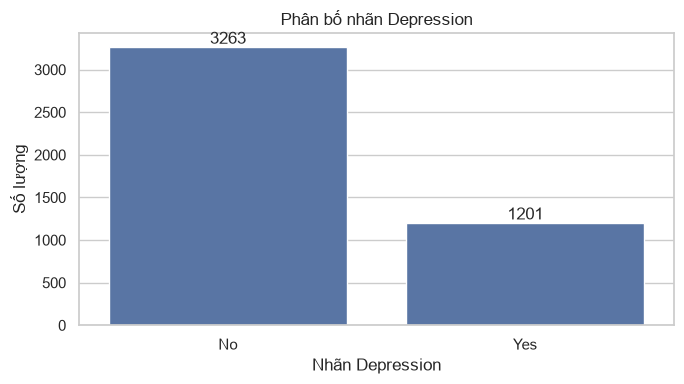

In [6]:
if "Depression" not in df.columns:
    raise KeyError("Không tìm thấy cột mục tiêu Depression.")

target_counts = df["Depression"].value_counts(dropna=False)
target_percent = df["Depression"].value_counts(normalize=True, dropna=False) * 100

target_summary = pd.DataFrame({
    "So_luong": target_counts,
    "Ty_le_%": target_percent.round(2)
})
display(target_summary)

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="Depression", order=df["Depression"].value_counts().index)
ax.set_title("Phân bố nhãn Depression")
ax.set_xlabel("Nhãn Depression")
ax.set_ylabel("Số lượng")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

**Nhận xét cần viết sau khi chạy (TODO):**
- Nhãn chiếm đa số là: `[điền từ kết quả]`.
- Tỷ lệ `Yes`: `[điền %]`; tỷ lệ `No`: `[điền %]`.
- Dữ liệu có mất cân bằng lớp hay không? Nêu bằng số liệu, không chỉ dựa vào hình.

## 6. Phân tích khám phá dữ liệu (EDA)

### 6.1. Phân bố các biến số

Các biến số: ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']


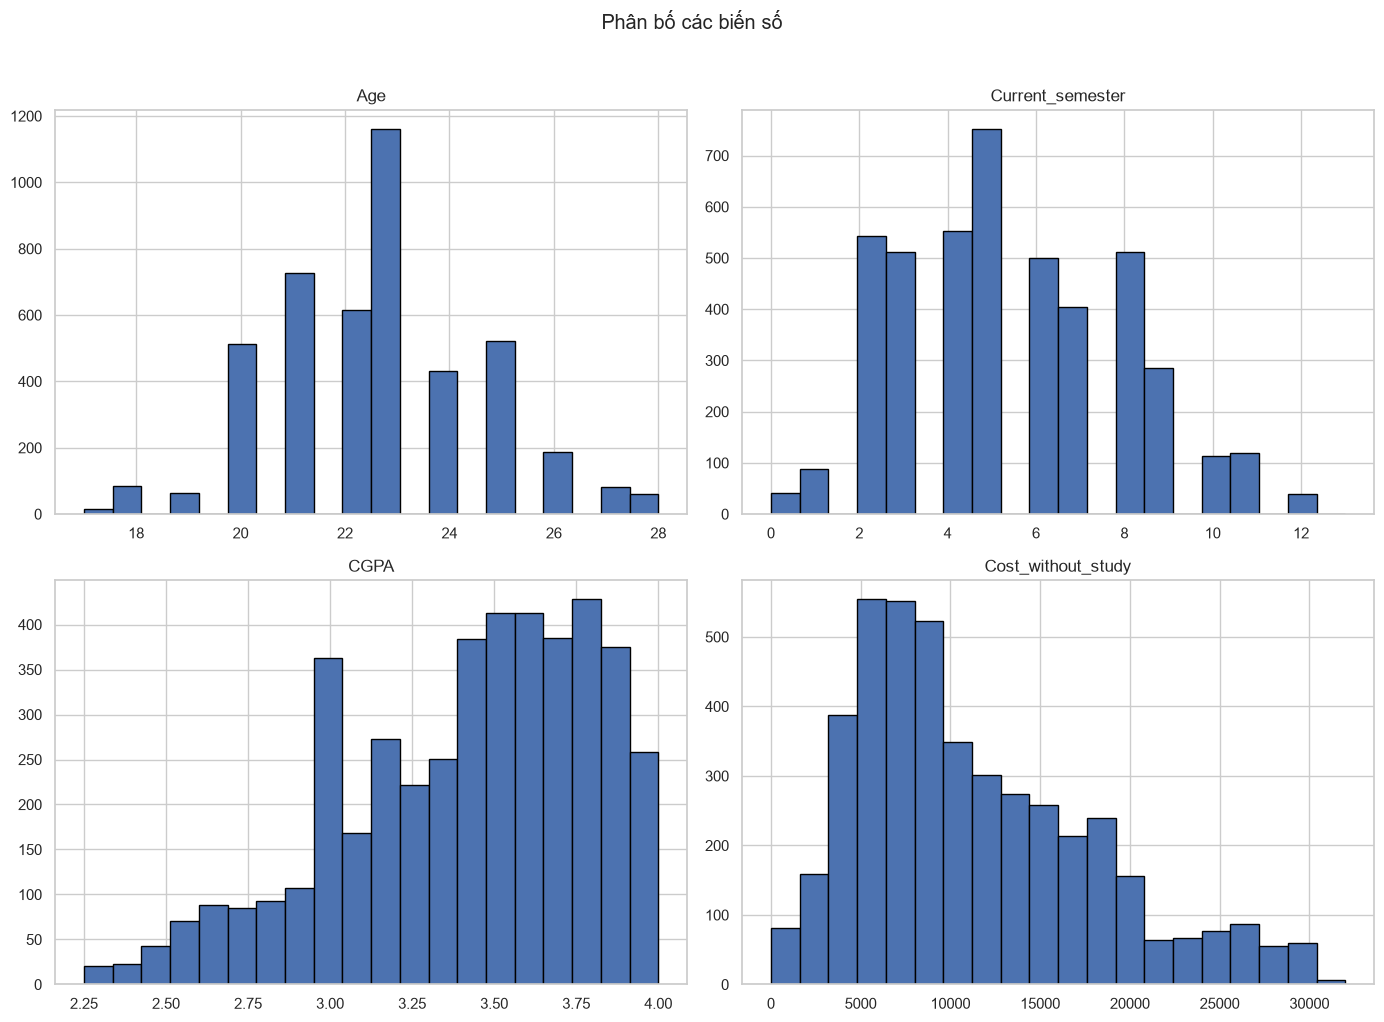

In [7]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Các biến số:", numeric_cols)

if numeric_cols:
    df[numeric_cols].hist(figsize=(14, 10), bins=20, edgecolor="black")
    plt.suptitle("Phân bố các biến số", y=1.02)
    plt.tight_layout()
    plt.show()

### 6.2. Phân bố các biến phân loại

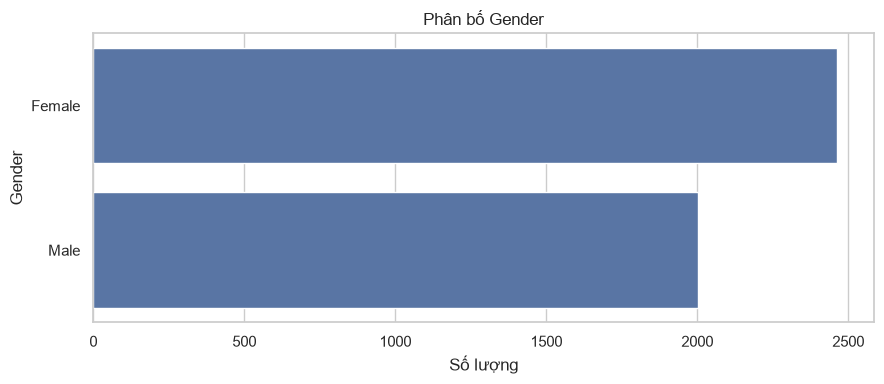

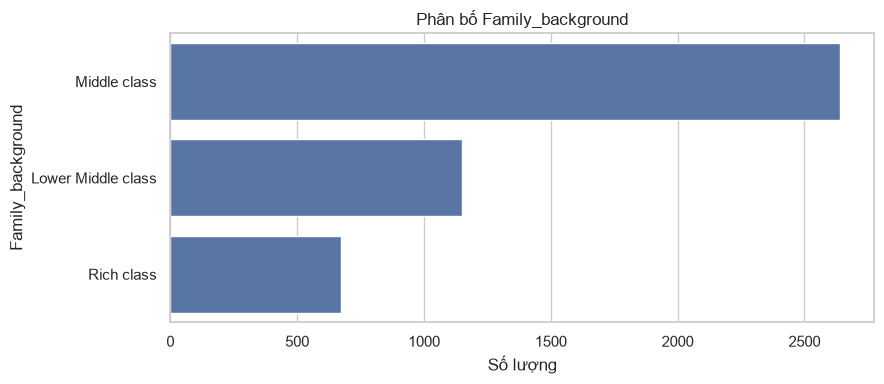

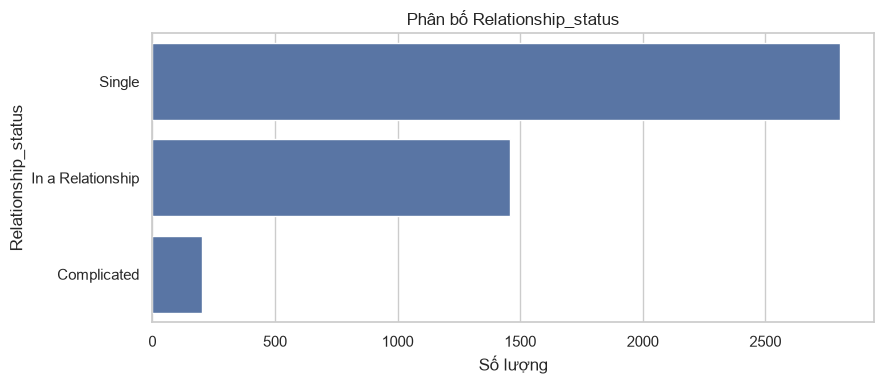

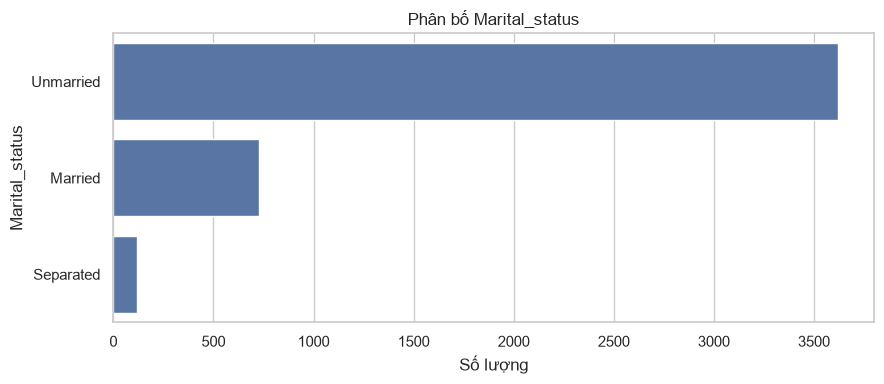

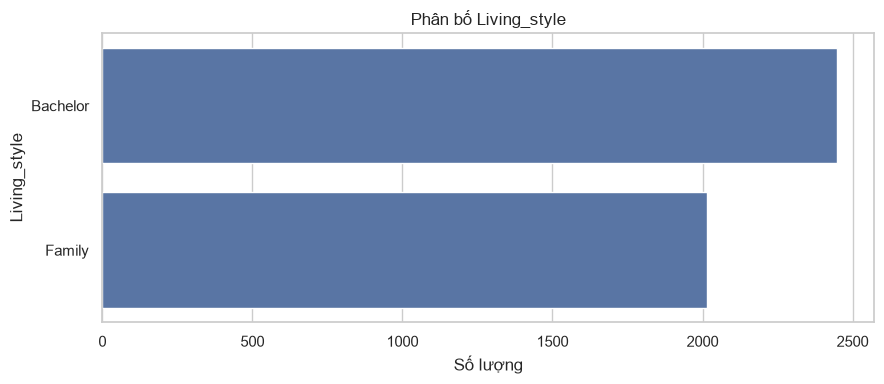

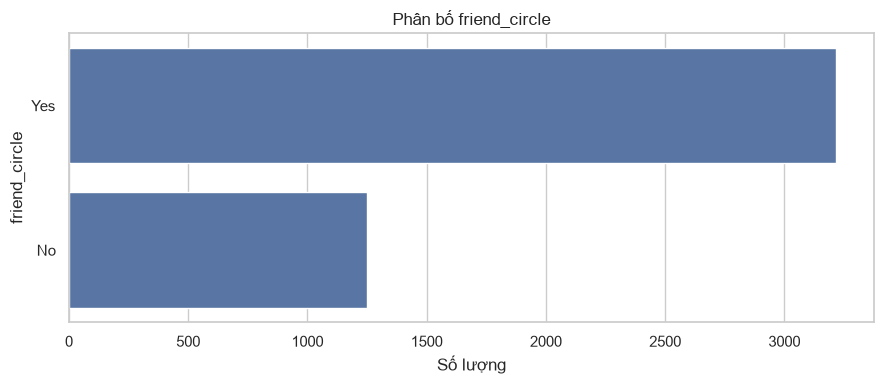

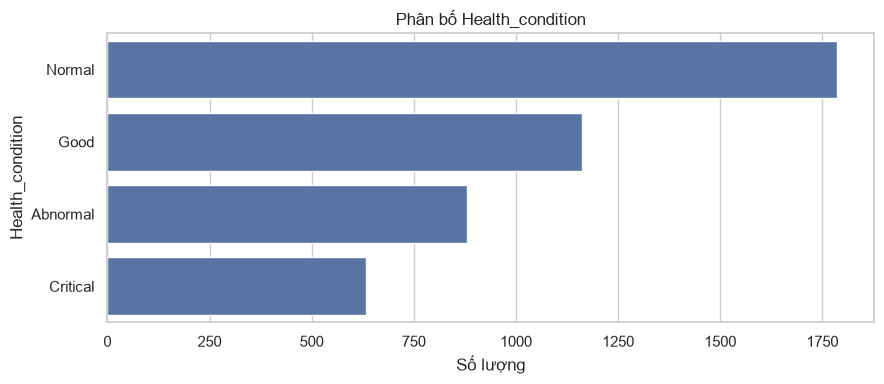

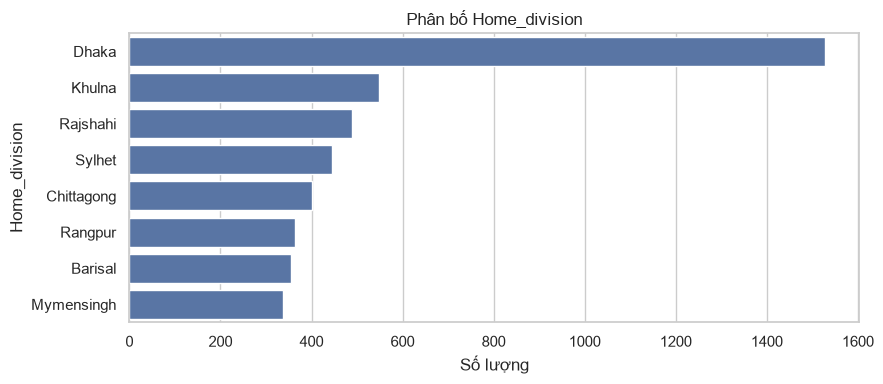

In [8]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()
categorical_cols = [c for c in categorical_cols if c != "Depression"]

for col in categorical_cols:
    plt.figure(figsize=(9, 4))
    order = df[col].value_counts().index
    ax = sns.countplot(data=df, y=col, order=order)
    ax.set_title(f"Phân bố {col}")
    ax.set_xlabel("Số lượng")
    ax.set_ylabel(col)
    plt.tight_layout()
    plt.show()

### 6.3. So sánh nhãn Depression theo từng thuộc tính

Depression,No,Yes
Gender,,
Male,72.7%,27.3%
Female,73.4%,26.6%


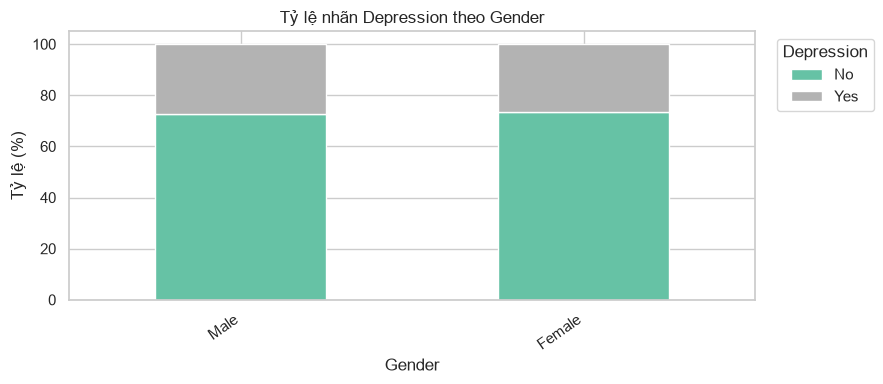

Depression,No,Yes
Family_background,,
Lower Middle class,69.4%,30.6%
Middle class,72.3%,27.7%
Rich class,82.4%,17.6%


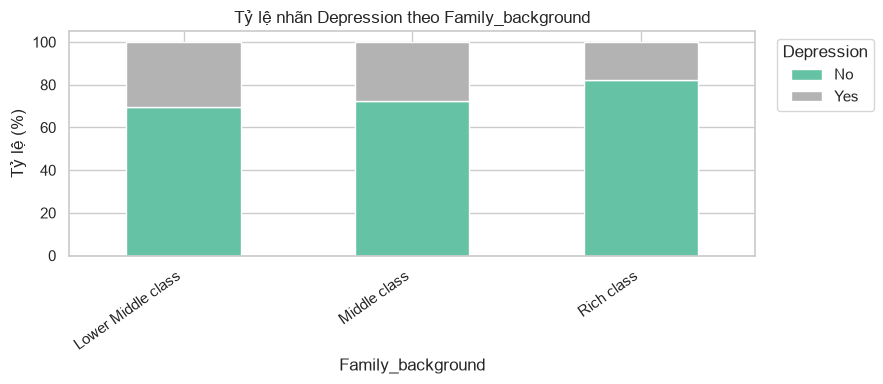

Depression,No,Yes
Relationship_status,,
Single,64.1%,35.9%
Complicated,86.8%,13.2%
In a Relationship,88.5%,11.5%


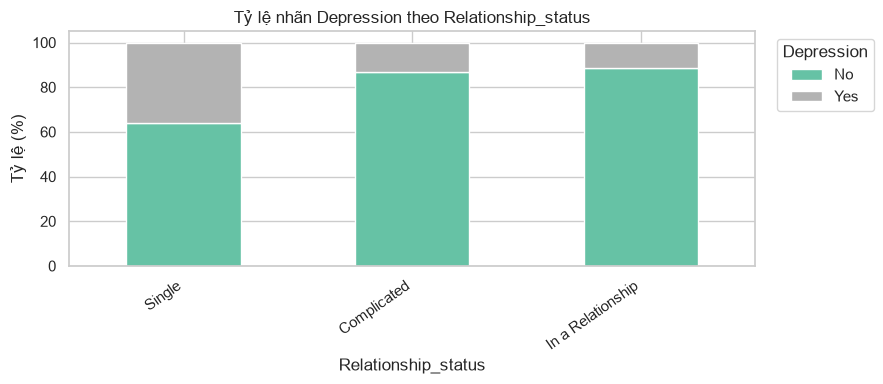

Depression,No,Yes
Marital_status,,
Unmarried,69.9%,30.1%
Separated,80.0%,20.0%
Married,88.0%,12.0%


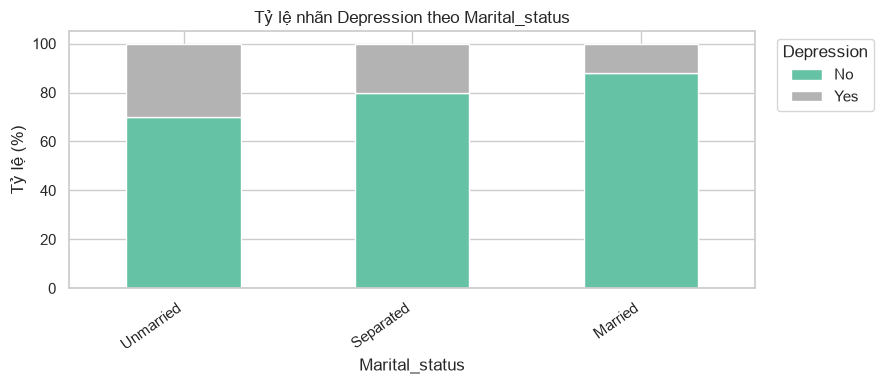

Depression,No,Yes
Living_style,,
Bachelor,71.7%,28.3%
Family,74.8%,25.2%


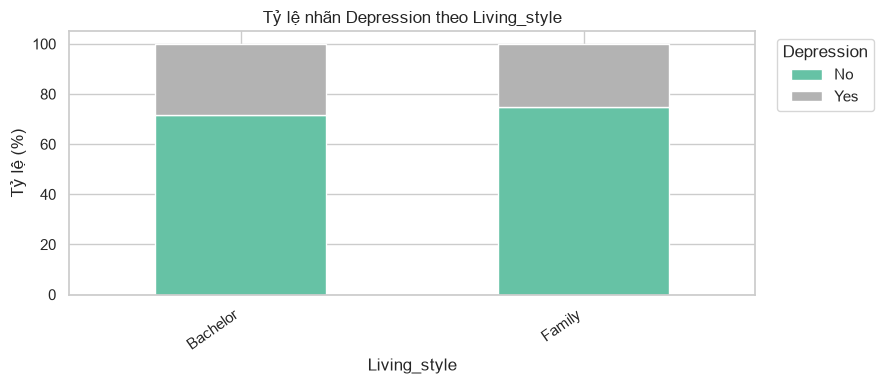

Depression,No,Yes
friend_circle,,
No,65.7%,34.3%
Yes,76.0%,24.0%


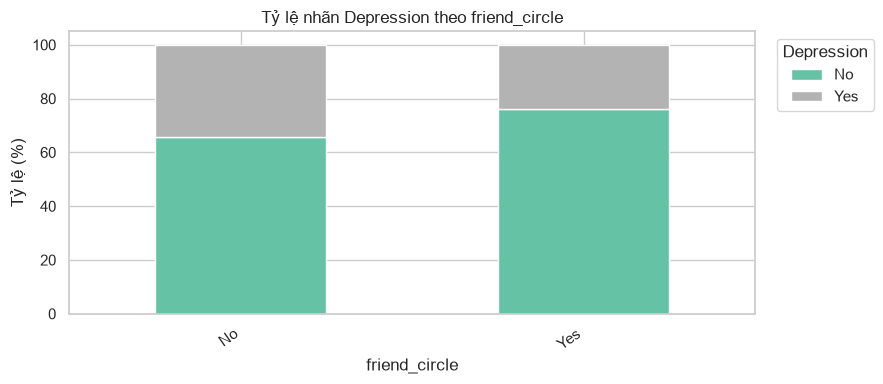

Depression,No,Yes
Health_condition,,
Critical,0.0%,100.0%
Abnormal,45.1%,54.9%
Normal,95.4%,4.6%
Good,100.0%,0.0%


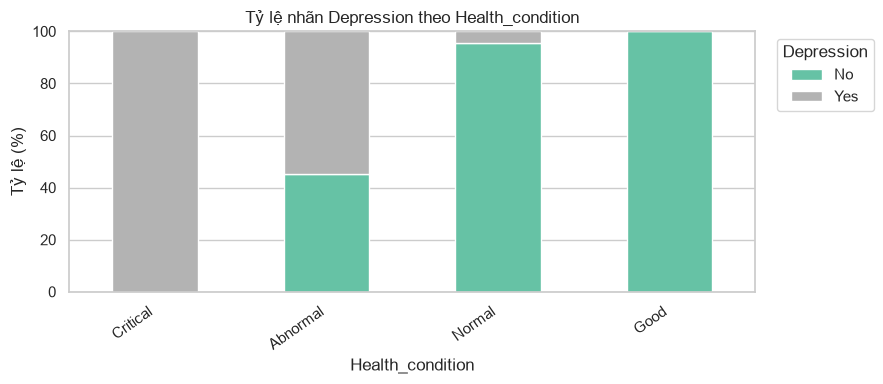

Depression,No,Yes
Home_division,,
Rangpur,68.0%,32.0%
Rajshahi,68.4%,31.6%
Khulna,69.0%,31.0%
Chittagong,69.5%,30.5%
Mymensingh,72.2%,27.8%
Barisal,72.4%,27.6%
Sylhet,76.4%,23.6%
Dhaka,77.6%,22.4%


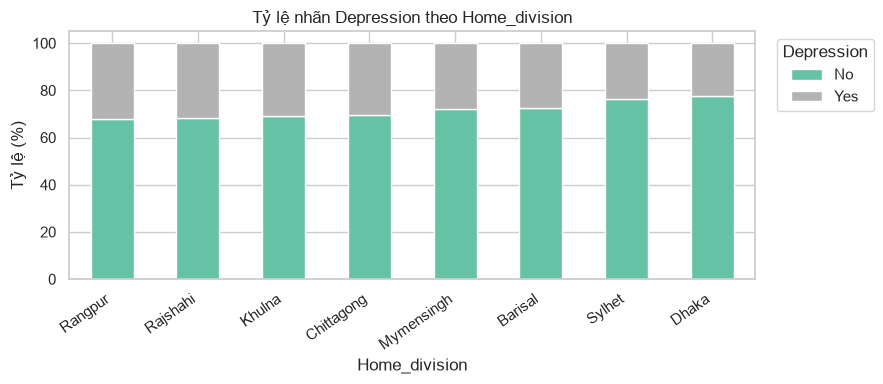

In [9]:
# Biểu đồ tỷ lệ trong từng nhóm để tránh chỉ so sánh số lượng tuyệt đối.
for col in categorical_cols:
    rate = pd.crosstab(df[col], df["Depression"], normalize="index") * 100
    if "Yes" in rate.columns:
        rate = rate.sort_values("Yes", ascending=False)
    display(rate.round(2).style.format("{:.1f}%"))

    ax = rate.plot(kind="bar", stacked=True, figsize=(9, 4), colormap="Set2")
    ax.set_title(f"Tỷ lệ nhãn Depression theo {col}")
    ax.set_ylabel("Tỷ lệ (%)")
    ax.set_xlabel(col)
    ax.legend(title="Depression", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

### 6.4. Biến số theo nhãn Depression

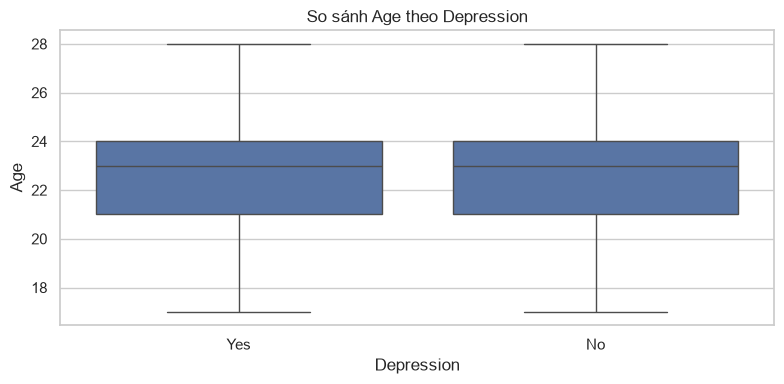

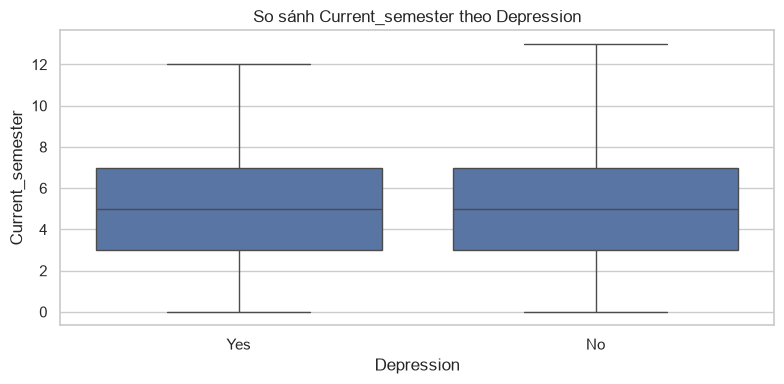

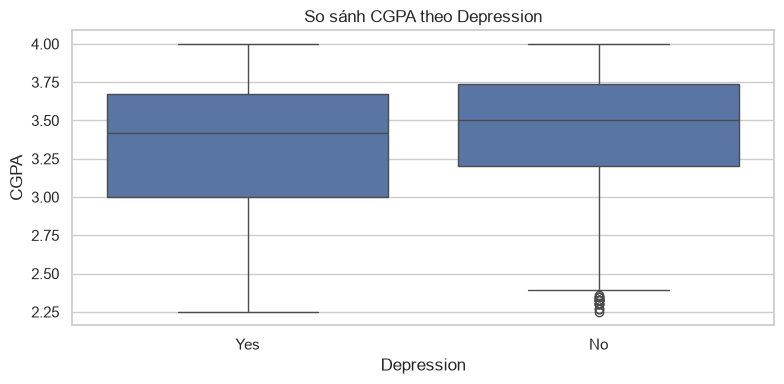

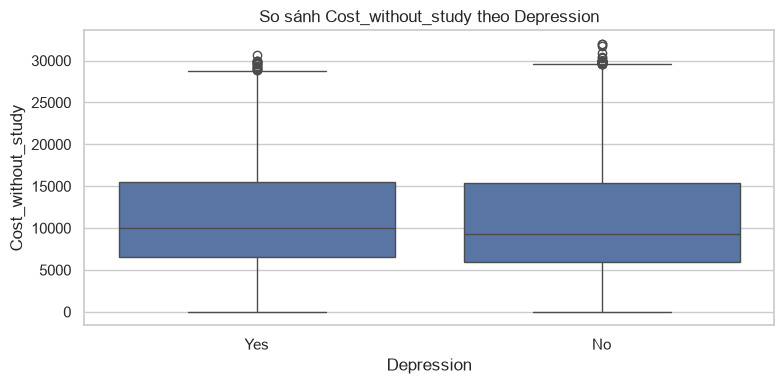

In [10]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x="Depression", y=col)
    plt.title(f"So sánh {col} theo Depression")
    plt.tight_layout()
    plt.show()

### 6.5. Tương quan giữa các biến số

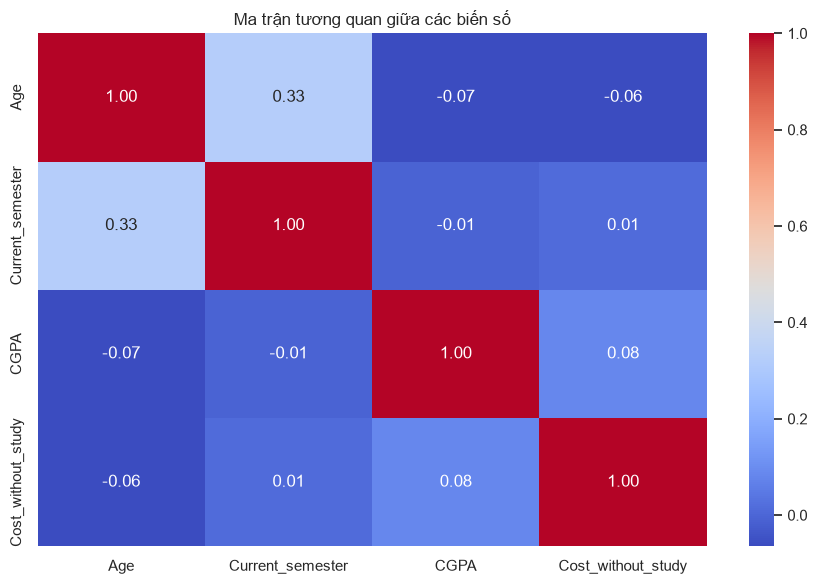

In [11]:
if len(numeric_cols) >= 2:
    plt.figure(figsize=(9, 6))
    sns.heatmap(df[numeric_cols].corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Ma trận tương quan giữa các biến số")
    plt.tight_layout()
    plt.show()

**Mẫu viết nhận xét EDA (TODO – phải thay bằng kết quả thực tế):**

1. Nhóm tuổi/học kỳ: mô tả nhóm xuất hiện nhiều nhất và phân bố nhãn theo nhóm.
2. CGPA: nêu xu hướng quan sát được từ biểu đồ, tránh kết luận quan hệ nhân quả.
3. `Health_condition`: mô tả phân bố và tỷ lệ nhãn theo nhóm; cần kiểm tra định nghĩa gốc.
4. Các thuộc tính còn lại: chọn 2–3 phát hiện nổi bật có số liệu minh chứng.
5. Phân biệt rõ **mối liên hệ trong dữ liệu** với **nguyên nhân gây trầm cảm**. EDA quan sát không chứng minh quan hệ nhân quả.

## 7. Chuẩn bị dữ liệu cho Machine Learning

### 7.1. Xác định X và y

`Depression` là biến mục tiêu nên được tách khỏi đặc trưng đầu vào. Các cột còn lại được dùng làm đặc trưng trong thí nghiệm ban đầu.

**Cảnh báo về rò rỉ dữ liệu (data leakage):** Nếu một cột được tạo ra từ chính kết quả khảo sát trầm cảm hoặc chứa thông tin gần như trực tiếp tiết lộ nhãn, mô hình có thể đạt điểm cao giả tạo. Cần đọc bảng hỏi và nguồn dữ liệu để quyết định có loại cột nào hay không. Đặc biệt cần xác minh `Health_condition` và mọi cột được đo sau/nhờ kết quả mục tiêu.

In [12]:
# Chuẩn hóa nhãn mục tiêu, chỉ chấp nhận hai nhãn Yes/No ở dataset hiện tại.
y_raw = df["Depression"].astype(str).str.strip()
observed_labels = sorted(y_raw.dropna().unique().tolist())
print("Nhãn quan sát:", observed_labels)

if set(observed_labels) != {"No", "Yes"}:
    raise ValueError(
        "Notebook hiện được cấu hình cho nhãn Yes/No. "
        f"Hãy kiểm tra và chỉnh sửa mapping cho nhãn: {observed_labels}"
    )

y = y_raw.map({"No": 0, "Yes": 1})
X = df.drop(columns=["Depression"]).copy()

# TODO: Sau khi xác minh bảng hỏi, liệt kê cột không được phép dùng làm đầu vào.
# Ví dụ: EXCLUDED_FEATURES = ["Ten_cot_can_loai"]
EXCLUDED_FEATURES = []
X = X.drop(columns=EXCLUDED_FEATURES, errors="ignore")

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("Tỷ lệ lớp:")
display(y.value_counts(normalize=True).rename(index={0:"No", 1:"Yes"}).to_frame("proportion"))

Nhãn quan sát: ['No', 'Yes']
Kích thước X: (4464, 12)
Kích thước y: (4464,)
Tỷ lệ lớp:


,proportion
Depression,
No,0.730959
Yes,0.269041


### 7.2. Chia tập train/test

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Tỷ lệ Yes train:", round(y_train.mean(), 3))
print("Tỷ lệ Yes test:", round(y_test.mean(), 3))

Train: (3571, 12) Test: (893, 12)
Tỷ lệ Yes train: 0.269
Tỷ lệ Yes test: 0.269


### 7.3. Xây dựng quy trình tiền xử lý

In [14]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Biến số:", numeric_features)
print("Biến phân loại:", categorical_features)

Biến số: ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
Biến phân loại: ['Gender', 'Family_background', 'Relationship_status', 'Marital_status', 'Living_style', 'friend_circle', 'Health_condition', 'Home_division']


## 8. Xây dựng mô hình phân loại

So sánh ba mô hình:
- **DummyClassifier:** mốc cơ sở, dự đoán theo lớp phổ biến.
- **Logistic Regression:** mô hình tuyến tính, dễ làm mốc so sánh.
- **Random Forest:** mô hình tổ hợp cây quyết định, có thể học quan hệ phi tuyến.

Dùng `class_weight='balanced'` cho Logistic Regression và Random Forest để giảm ảnh hưởng của chênh lệch số lượng lớp. Không mặc định mô hình phức tạp hơn là tốt hơn.

In [15]:
models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        min_samples_leaf=2
    )
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"Đã huấn luyện: {name}")

Đã huấn luyện: Dummy
Đã huấn luyện: Logistic Regression
Đã huấn luyện: Random Forest


## 9. Đánh giá mô hình trên tập test

Các chỉ số:
- **Accuracy:** tỷ lệ dự đoán đúng trên toàn bộ mẫu.
- **Precision (lớp Yes):** trong các mẫu mô hình dự đoán Yes, có bao nhiêu mẫu thật sự mang nhãn Yes.
- **Recall (lớp Yes):** trong các mẫu có nhãn Yes, mô hình tìm được bao nhiêu.
- **F1-score:** trung bình điều hòa Precision và Recall.
- **ROC-AUC:** khả năng xếp hạng phân biệt hai lớp nếu mô hình cung cấp xác suất.

Với bài toán liên quan sức khỏe, không nên chỉ nhìn Accuracy. Cần thảo luận cân bằng Precision/Recall và hậu quả của dự đoán sai. Những chỉ số này chỉ đo sự phù hợp với nhãn trong dataset.

In [16]:
results = []
test_predictions = {}

for name, pipe in pipelines.items():
    pred = pipe.predict(X_test)
    test_predictions[name] = pred

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_Yes": precision_score(y_test, pred, zero_division=0),
        "Recall_Yes": recall_score(y_test, pred, zero_division=0),
        "F1_Yes": f1_score(y_test, pred, zero_division=0)
    }

    if hasattr(pipe, "predict_proba"):
        prob = pipe.predict_proba(X_test)[:, 1]
        row["ROC_AUC"] = roc_auc_score(y_test, prob)
    else:
        row["ROC_AUC"] = np.nan

    results.append(row)

results_df = pd.DataFrame(results).sort_values("F1_Yes", ascending=False)
display(results_df.style.format({
    "Accuracy":"{:.3f}", "Precision_Yes":"{:.3f}",
    "Recall_Yes":"{:.3f}", "F1_Yes":"{:.3f}", "ROC_AUC":"{:.3f}"
}))

,Model,Accuracy,Precision_Yes,Recall_Yes,F1_Yes,ROC_AUC
2,Random Forest,0.991,0.996,0.971,0.983,0.999
1,Logistic Regression,0.969,0.927,0.958,0.943,0.993
0,Dummy,0.731,0.000,0.000,0.000,0.500


### 9.1. Classification report và Confusion Matrix


Dummy
              precision    recall  f1-score   support

          No       0.73      1.00      0.84       653
         Yes       0.00      0.00      0.00       240

    accuracy                           0.73       893
   macro avg       0.37      0.50      0.42       893
weighted avg       0.53      0.73      0.62       893



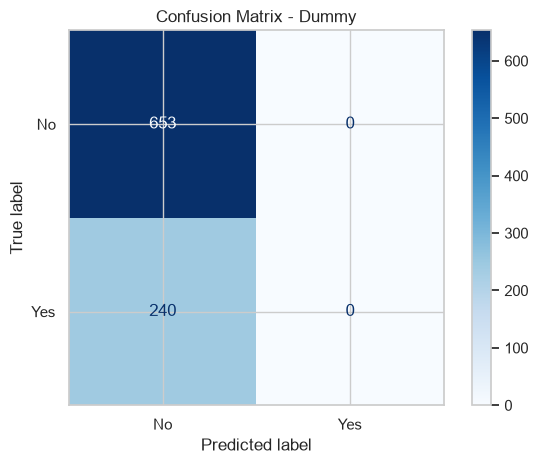


Logistic Regression
              precision    recall  f1-score   support

          No       0.98      0.97      0.98       653
         Yes       0.93      0.96      0.94       240

    accuracy                           0.97       893
   macro avg       0.96      0.97      0.96       893
weighted avg       0.97      0.97      0.97       893



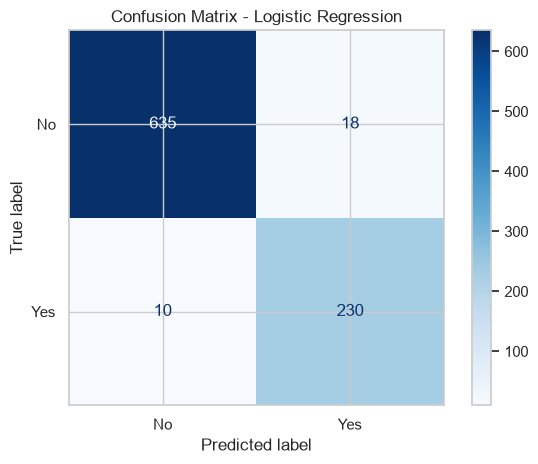


Random Forest
              precision    recall  f1-score   support

          No       0.99      1.00      0.99       653
         Yes       1.00      0.97      0.98       240

    accuracy                           0.99       893
   macro avg       0.99      0.98      0.99       893
weighted avg       0.99      0.99      0.99       893



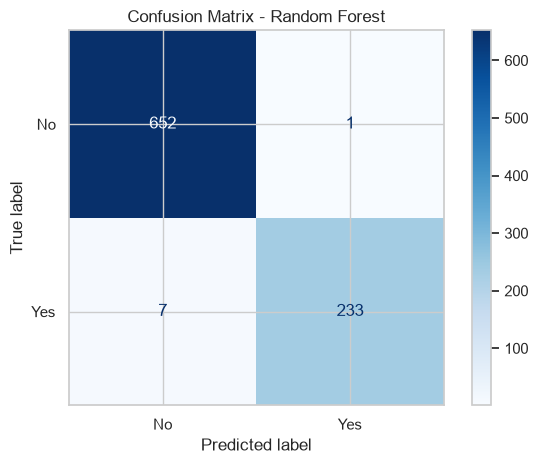

In [17]:
for name, pipe in pipelines.items():
    print("\n" + "="*65)
    print(name)
    pred = test_predictions[name]
    print(classification_report(
        y_test, pred,
        labels=[0, 1],
        target_names=["No", "Yes"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No", "Yes"])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

### 9.2. ROC Curve

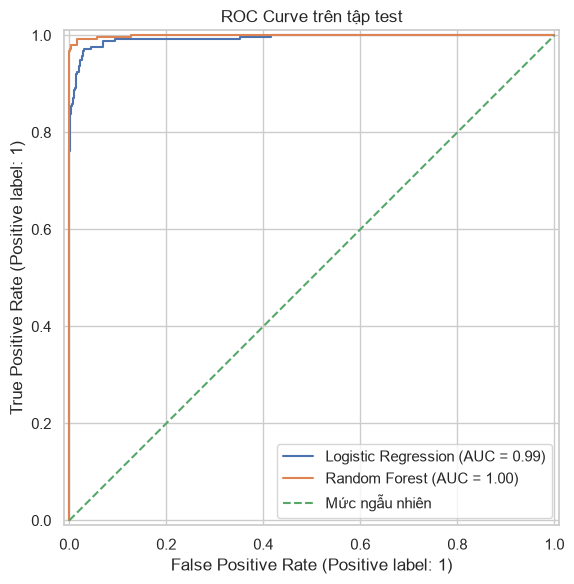

In [18]:
plt.figure(figsize=(7, 6))
for name, pipe in pipelines.items():
    if hasattr(pipe, "predict_proba") and name != "Dummy":
        RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], linestyle="--", label="Mức ngẫu nhiên")
plt.title("ROC Curve trên tập test")
plt.tight_layout()
plt.legend()
plt.show()

### 9.3. Đánh giá chéo trên tập huấn luyện (Cross-validation)

Cross-validation hỗ trợ đánh giá độ ổn định trên nhiều lần chia dữ liệu trong tập train. Tập test vẫn được giữ riêng để đánh giá cuối cùng.

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv, scoring=scoring,
        n_jobs=-1, error_score="raise"
    )
    cv_rows.append({
        "Model": name,
        **{f"{metric}_mean": scores[f"test_{metric}"].mean() for metric in scoring},
        **{f"{metric}_std": scores[f"test_{metric}"].std() for metric in scoring}
    })

cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(3))

,Model,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,accuracy_std,precision_std,recall_std,f1_std,roc_auc_std
0,Dummy,0.731,0.000,0.000,0.000,0.500,0.000,0.000,0.000,0.000,0.000
1,Logistic Regression,0.965,0.913,0.963,0.937,0.991,0.008,0.026,0.009,0.014,0.002
2,Random Forest,0.989,0.992,0.968,0.979,0.999,0.003,0.008,0.006,0.006,0.000


## 10. Chọn mô hình và phân tích đặc trưng

Chọn mô hình dựa trên mục tiêu phân tích, các chỉ số test và kết quả cross-validation; không chọn chỉ dựa vào một chỉ số đơn lẻ. Trong notebook này, mô hình có F1 lớp Yes cao nhất trên tập test được chọn để minh họa. Người làm cần xem xét thêm Recall, Precision và độ ổn định CV trước khi kết luận.

In [20]:
best_model_name = results_df.iloc[0]["Model"]
best_model = pipelines[best_model_name]

print("Mô hình đứng đầu theo F1_Yes trên tập test:", best_model_name)
print("Kết quả:")
display(results_df[results_df["Model"] == best_model_name])

Mô hình đứng đầu theo F1_Yes trên tập test: Random Forest
Kết quả:


,Model,Accuracy,Precision_Yes,Recall_Yes,F1_Yes,ROC_AUC
2,Random Forest,0.991041,0.995726,0.970833,0.983122,0.999005


### 10.1. Permutation Importance

,Feature,Importance_mean,Importance_std
9,Health_condition,0.663849,0.020891
3,Relationship_status,0.122807,0.013861
4,Marital_status,0.049775,0.003634
8,friend_circle,0.039858,0.004975
7,CGPA,0.029297,0.005746
2,Family_background,0.027013,0.004900
6,Current_semester,0.020547,0.006055
10,Cost_without_study,0.006356,0.002537
5,Living_style,0.002309,0.001479
0,Gender,0.000860,0.001053


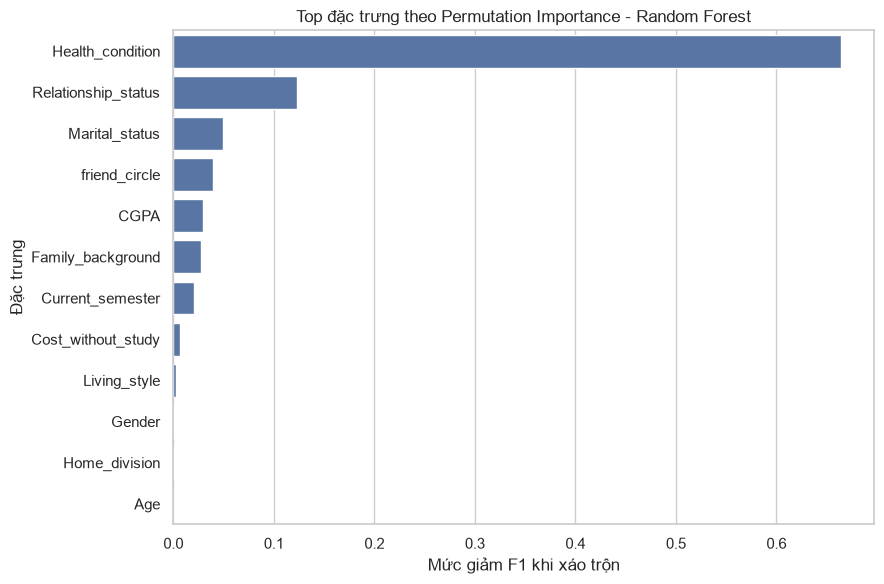

In [21]:
# Permutation importance đo mức giảm điểm khi xáo trộn từng cột đầu vào.
# Tính trên test set; kết quả có thể dao động theo mẫu và metric.
perm = permutation_importance(
    best_model,
    X_test, y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="f1",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_mean": perm.importances_mean,
    "Importance_std": perm.importances_std
}).sort_values("Importance_mean", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df.head(15), x="Importance_mean", y="Feature")
plt.title(f"Top đặc trưng theo Permutation Importance - {best_model_name}")
plt.xlabel("Mức giảm F1 khi xáo trộn")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

**Cách diễn giải:** Importance cao nghĩa là mô hình đang phụ thuộc nhiều hơn vào cột đó trong tập đánh giá. Điều này **không chứng minh** cột đó gây ra trầm cảm, cũng không chứng minh đây là yếu tố nguy cơ độc lập. Nếu có biến nhạy cảm hoặc biến gần với nhãn, cần đánh giá lại việc sử dụng chúng.

## 11. Thử dự đoán trên một dòng dữ liệu

In [22]:
# Chọn một dòng từ tập test để minh họa cách gọi predict.
# Đây chỉ là minh họa kỹ thuật, không dùng để đánh giá sức khỏe một cá nhân.
sample = X_test.iloc[[0]]
actual_label = "Yes" if y_test.iloc[0] == 1 else "No"
predicted_value = best_model.predict(sample)[0]
predicted_label = "Yes" if predicted_value == 1 else "No"

print("Nhãn trong dataset:", actual_label)
print("Nhãn mô hình dự đoán:", predicted_label)

if hasattr(best_model, "predict_proba"):
    print("Xác suất mô hình gán cho nhãn Yes:", round(best_model.predict_proba(sample)[0, 1], 4))

display(sample)

Nhãn trong dataset: No
Nhãn mô hình dự đoán: No
Xác suất mô hình gán cho nhãn Yes: 0.0051


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division
4305,Male,24,Middle class,Single,Unmarried,Bachelor,5,3.76,Yes,Normal,11164,Sylhet


### 11.1. Dự đoán với dữ liệu mới do người dùng nhập

Chỉnh các giá trị mẫu dưới đây theo đúng kiểu dữ liệu và các nhóm giá trị có trong CSV. Không nhập thông tin định danh cá nhân. Đầu ra chỉ là dự đoán nhãn của mô hình, không phải kết luận y khoa.

In [23]:
# TODO: Thay các giá trị ví dụ bằng một dòng dữ liệu giả lập phù hợp với dataset.
# Giữ đúng tên cột. Các giá trị phân loại nên nằm trong những nhóm đã thấy ở EDA.
new_student = pd.DataFrame([{
    "Gender": "Female",
    "Age": 22,
    "Family_background": "Middle class",
    "Relationship_status": "Single",
    "Marital_status": "Unmarried",
    "Living_style": "Bachelor",
    "Current_semester": 5,
    "CGPA": 3.50,
    "friend_circle": "Yes",
    "Health_condition": "Normal",
    "Cost_without_study": 10000,
    "Home_division": "Dhaka"
}])

# Đảm bảo đúng thứ tự/các cột đặc trưng đã dùng khi huấn luyện.
new_student = new_student.reindex(columns=X.columns)

new_prediction = best_model.predict(new_student)[0]
print("Nhãn mô hình dự đoán:", "Yes" if new_prediction == 1 else "No")

if hasattr(best_model, "predict_proba"):
    print("Xác suất mô hình cho nhãn Yes:", best_model.predict_proba(new_student)[0, 1])

print("LƯU Ý: Đây là kết quả phân loại theo dữ liệu huấn luyện, không phải chẩn đoán.")

Nhãn mô hình dự đoán: No
Xác suất mô hình cho nhãn Yes: 0.007540004271503322
LƯU Ý: Đây là kết quả phân loại theo dữ liệu huấn luyện, không phải chẩn đoán.


## 12. Lưu mô hình

In [24]:
MODEL_PATH = Path("best_student_depression_model.joblib")
joblib.dump(best_model, MODEL_PATH)
print("Đã lưu mô hình tại:", MODEL_PATH.resolve())

Đã lưu mô hình tại: D:\PTDL&AI\Báo cáo cuối kì\BaoCaoCuoiKy\notebooks\best_student_depression_model.joblib


## 13. Kết luận và thảo luận

### 13.1. Kết quả chính (TODO)
- Quy mô dữ liệu sau làm sạch: `[điền số dòng]`.
- Tỷ lệ nhãn Yes/No: `[điền số liệu]`.
- Mô hình được chọn: `[điền tên mô hình]`.
- Accuracy: `[điền]`.
- Precision lớp Yes: `[điền]`.
- Recall lớp Yes: `[điền]`.
- F1 lớp Yes: `[điền]`.
- ROC-AUC: `[điền]`.

### 13.2. Thảo luận (TODO)
- Mô hình nào tốt hơn baseline Dummy? Dựa trên chỉ số nào?
- Mô hình có Recall lớp Yes phù hợp với mục tiêu bài tập không?
- Kết quả cross-validation có ổn định không?
- Các biến quan trọng nhất là gì? Có hợp lý theo dữ liệu và định nghĩa cột không?
- Có dấu hiệu data leakage, thiên lệch mẫu hoặc mất cân bằng lớp không?

### 13.3. Hạn chế
1. Chất lượng kết quả phụ thuộc vào nguồn, cách lấy mẫu và cách gán nhãn của dataset.
2. Các cột trong file không cho biết đầy đủ bối cảnh cá nhân và đánh giá lâm sàng.
3. Quan hệ thống kê không đồng nghĩa quan hệ nhân quả.
4. Kết quả không thể khái quát cho mọi sinh viên nếu chưa kiểm định trên dữ liệu độc lập, đại diện.
5. Không dùng mô hình này để sàng lọc, chẩn đoán, quyết định điều trị hoặc gắn nhãn một cá nhân.

### 13.4. Hướng phát triển
- Xác minh tài liệu mô tả dữ liệu và định nghĩa từng biến.
- Đánh giá fairness giữa các nhóm nếu có cơ sở và được phép sử dụng.
- Thử nghiệm thêm mô hình/siêu tham số với quy trình cross-validation phù hợp.
- Kiểm định trên tập dữ liệu độc lập và có quy trình quản trị dữ liệu phù hợp.
- Nếu hướng tới ứng dụng sức khỏe, cần chuyên gia chuyên môn, thẩm định đạo đức, bảo mật và quy trình hỗ trợ con người.

## 14. Tài liệu tham khảo và thông tin cần bổ sung

- **Tên file:** `Student_Depression_Dataset.csv`
- **Nguồn tải:** `TODO – điền URL/trang phát hành chính thức`.
- **Tác giả/đơn vị phát hành:** `TODO`.
- **Ngày truy cập:** `TODO`.
- **Giấy phép/quyền sử dụng:** `TODO – kiểm tra trước khi chia sẻ công khai trên GitHub`.
- **Phiên bản Python và thư viện:** ghi lại môi trường thực tế khi hoàn thiện.

**TODO:** Nếu dataset không được phép công khai, không đưa file CSV lên repository public. Có thể thêm đường dẫn tải hợp lệ hoặc hướng dẫn đặt dữ liệu vào thư mục `data/`.

---
**Kết thúc notebook.** Trước khi nộp, hãy chạy lại toàn bộ notebook bằng `Restart & Run All`, kiểm tra không còn lỗi, thay các ghi chú TODO và đảm bảo README khớp với kết quả thực tế.